# SISPS-BATT-INT-CAL

Calibration of SISPS Battery Interposer for Lead Acid Battery Freezing Extent Measurement.

## Setup

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

from typing import List

In [17]:
plt.rcParams.update(
    {
        "figure.dpi": 600,
    }
)

## Data Import

In [18]:
SERIAL_DATA_PATH = "../Data/Serial"
VBATT_DATA_PATH = "../Data/VBATT"

## VBAT Data



In [19]:
def load_vbatt_data(file_path):
    file = os.listdir(file_path)[0]
    df = pd.read_csv(
        os.path.join(file_path, file),
        index_col=0,
    )
    return df


vbatt_df = load_vbatt_data(VBATT_DATA_PATH)

## Serial Data

In [20]:
def load_serial_data(file_path: str) -> pd.DataFrame:
    """
    Load serial data from a Text file and return it as a DataFrame.
    """
    HEADER_LINES = 23

    result = {}
    TEST = os.path.basename(file_path).split(" ")[0]
    BATTERY = os.path.basename(file_path).split(" ")[1]

    print(f"Loading serial data from: {file_path} for test: {TEST}")
    with open(file_path, "r") as file:
        content = file.read()

        lines = content.splitlines()
        header = "\n".join(lines[:HEADER_LINES])
        data = "\n".join(lines[HEADER_LINES:])

    result["test"] = TEST
    result["battery"] = BATTERY
    result["header"] = header

    def parse_data(data: str) -> pd.DataFrame:
        VARIABLES = ["Temp+", "Temp-", "Delta T", "Vrms", "VrmsNull", "Vbatt"]
        dataframe = pd.DataFrame(columns=VARIABLES)

        line_number = 0
        for line in data.splitlines():
            for var in VARIABLES:
                data_point = line.split(f"{var}:")[1].split()[0]
                dataframe.at[line_number, var] = float(data_point)

            line_number += 1

        return dataframe

    result = parse_data(data)
    result.attrs = {"test": TEST, "battery": BATTERY, "header": header}

    return result


dataframes = []

for file_name in os.listdir(SERIAL_DATA_PATH):
    if file_name.endswith(".txt"):
        file_path = os.path.join(SERIAL_DATA_PATH, file_name)
        df = load_serial_data(file_path)
        dataframes.append(df)

Loading serial data from: ../Data/Serial/T07 C07 Serial Output.txt for test: T07
Loading serial data from: ../Data/Serial/T22 C08 Serial Output.txt for test: T22
Loading serial data from: ../Data/Serial/T01 C01 Serial Output.txt for test: T01
Loading serial data from: ../Data/Serial/T21 C07 Serial Output.txt for test: T21
Loading serial data from: ../Data/Serial/T28 C14 Serial Output.txt for test: T28
Loading serial data from: ../Data/Serial/T15 C01 Serial Output.txt for test: T15
Loading serial data from: ../Data/Serial/T26 C12 Serial Output.txt for test: T26
Loading serial data from: ../Data/Serial/T10 C10 Serial Output.txt for test: T10
Loading serial data from: ../Data/Serial/T19 C05 Serial Output.txt for test: T19
Loading serial data from: ../Data/Serial/T12 C12 Serial Output.txt for test: T12
Loading serial data from: ../Data/Serial/T14 C14 Serial Output.txt for test: T14
Loading serial data from: ../Data/Serial/T17 C03 Serial Output.txt for test: T17
Loading serial data from: ..

### Data Preprocessing

In [21]:
dataframes.sort(key=lambda df: df.attrs["test"])

for df in dataframes:
    df["Vrms"] = df["Vrms"] / 1000
    df["VrmsNull"] = df["VrmsNull"] / 1000
    df["Delta T"] = df["Delta T"] / 1000

## Impedance

In [22]:
import re


def get_vrms(vrms_list: list) -> float:
    return pd.Series(vrms_list).tail(3).mean()


def get_current(header: str) -> float:
    match = re.search(r"EIS Current: ([\d.]+) A", header)
    if not match:
        raise ValueError(f"EIS Current not found in header:\n{header}")
    return float(match.group(1))


def impedance(vrms: float, vrms_null: float, current: float) -> float:
    return (vrms - vrms_null) / current


impedances = {}

for df in dataframes:
    test = df.attrs["test"]
    battery = df.attrs["battery"]
    vrms = get_vrms(df["Vrms"])
    vrms_null = get_vrms(df["VrmsNull"])
    current = get_current(df.attrs["header"])

    impedances[test] = impedance(vrms, vrms_null, current)

    print(
        f"Test: {test}, Battery: {battery}, Vrms: {vrms:.6f} V, VrmsNull: {vrms_null:.6f} V, Current: {current:.3f} A, Impedance: {impedances[test]:.6f} Ohms"
    )

Test: T01, Battery: C01, Vrms: 0.034391 V, VrmsNull: 0.002164 V, Current: 0.150 A, Impedance: 0.214847 Ohms
Test: T02, Battery: C02, Vrms: 0.031371 V, VrmsNull: 0.002179 V, Current: 0.150 A, Impedance: 0.194613 Ohms
Test: T03, Battery: C03, Vrms: 0.034438 V, VrmsNull: 0.002163 V, Current: 0.150 A, Impedance: 0.215164 Ohms
Test: T04, Battery: C04, Vrms: 0.029949 V, VrmsNull: 0.002174 V, Current: 0.150 A, Impedance: 0.185167 Ohms
Test: T05, Battery: C05, Vrms: 0.030191 V, VrmsNull: 0.002188 V, Current: 0.150 A, Impedance: 0.186691 Ohms
Test: T06, Battery: C06, Vrms: 0.025251 V, VrmsNull: 0.002164 V, Current: 0.150 A, Impedance: 0.153916 Ohms
Test: T07, Battery: C07, Vrms: 0.033803 V, VrmsNull: 0.002167 V, Current: 0.150 A, Impedance: 0.210904 Ohms
Test: T08, Battery: C08, Vrms: 0.025107 V, VrmsNull: 0.002188 V, Current: 0.150 A, Impedance: 0.152793 Ohms
Test: T09, Battery: C09, Vrms: 0.027807 V, VrmsNull: 0.002175 V, Current: 0.150 A, Impedance: 0.170880 Ohms
Test: T10, Battery: C10, Vrm

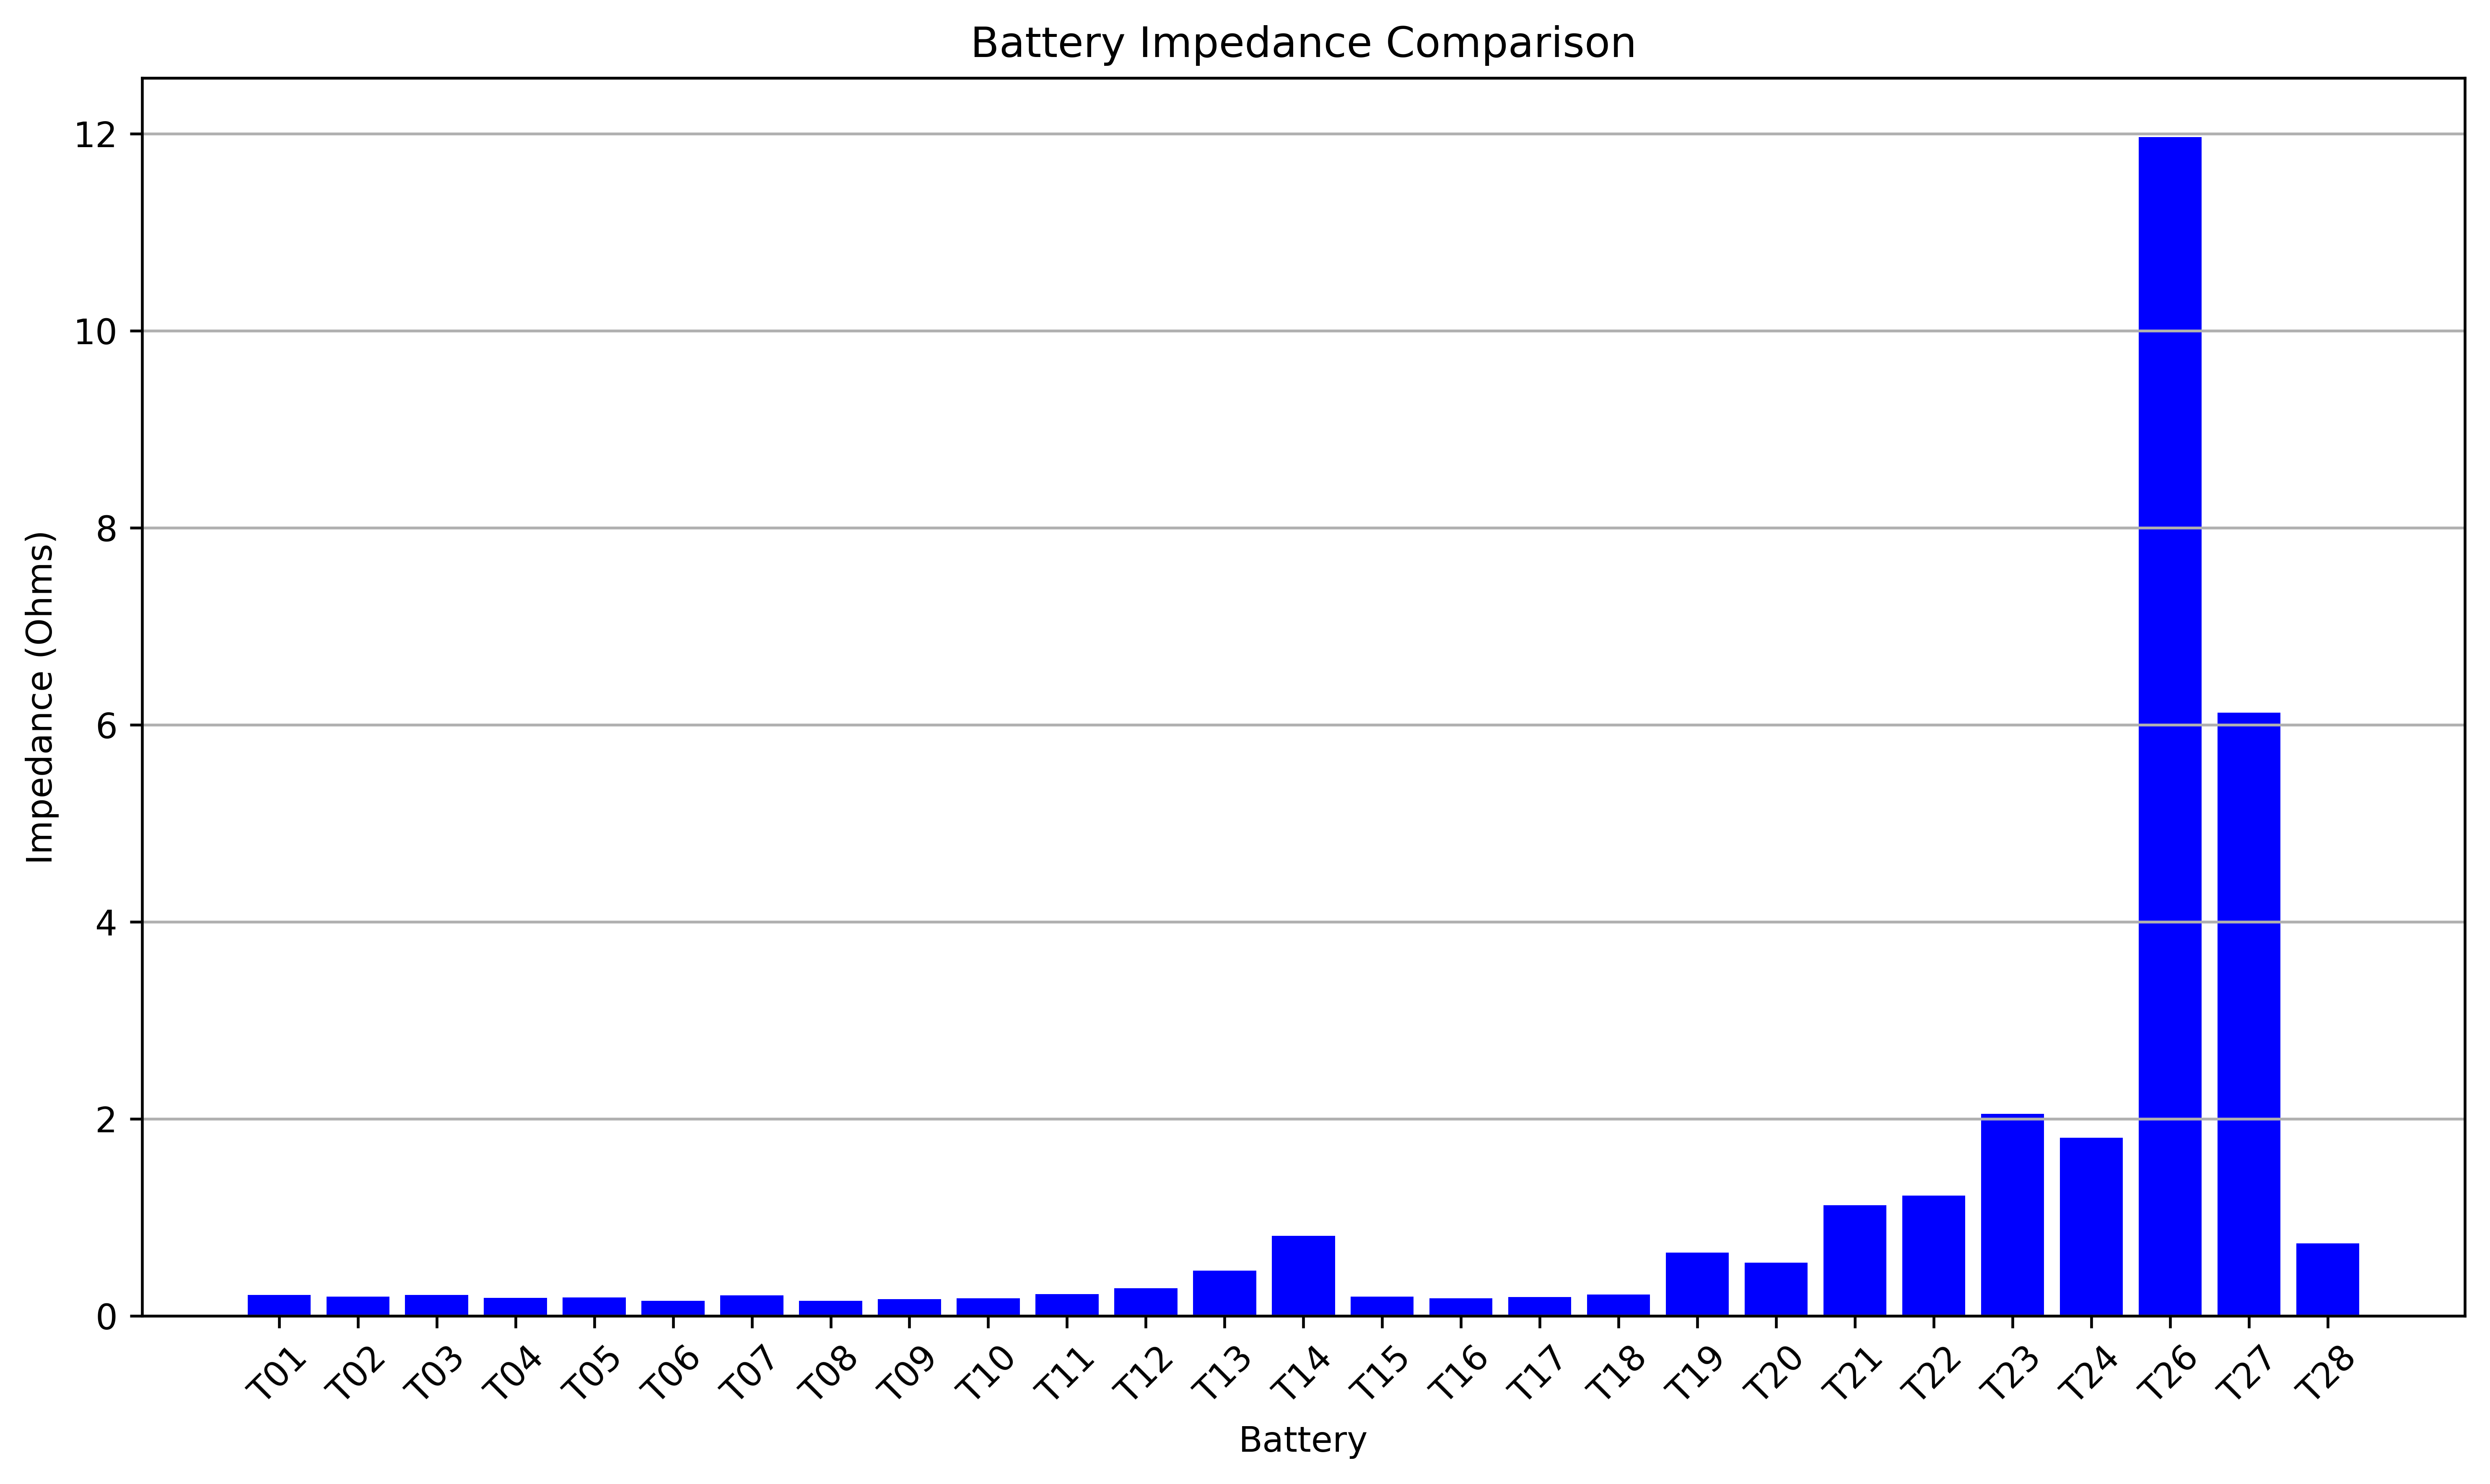

In [23]:
def plot_impedances(impedances: dict):
    tests = list(impedances.keys())
    impedance_values = list(impedances.values())

    plt.figure(figsize=(10, 6))
    plt.bar(tests, impedance_values, color="blue")
    plt.xlabel("Battery")
    plt.ylabel("Impedance (Ohms)")
    plt.title("Battery Impedance Comparison")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_impedances(impedances)

## Conditions

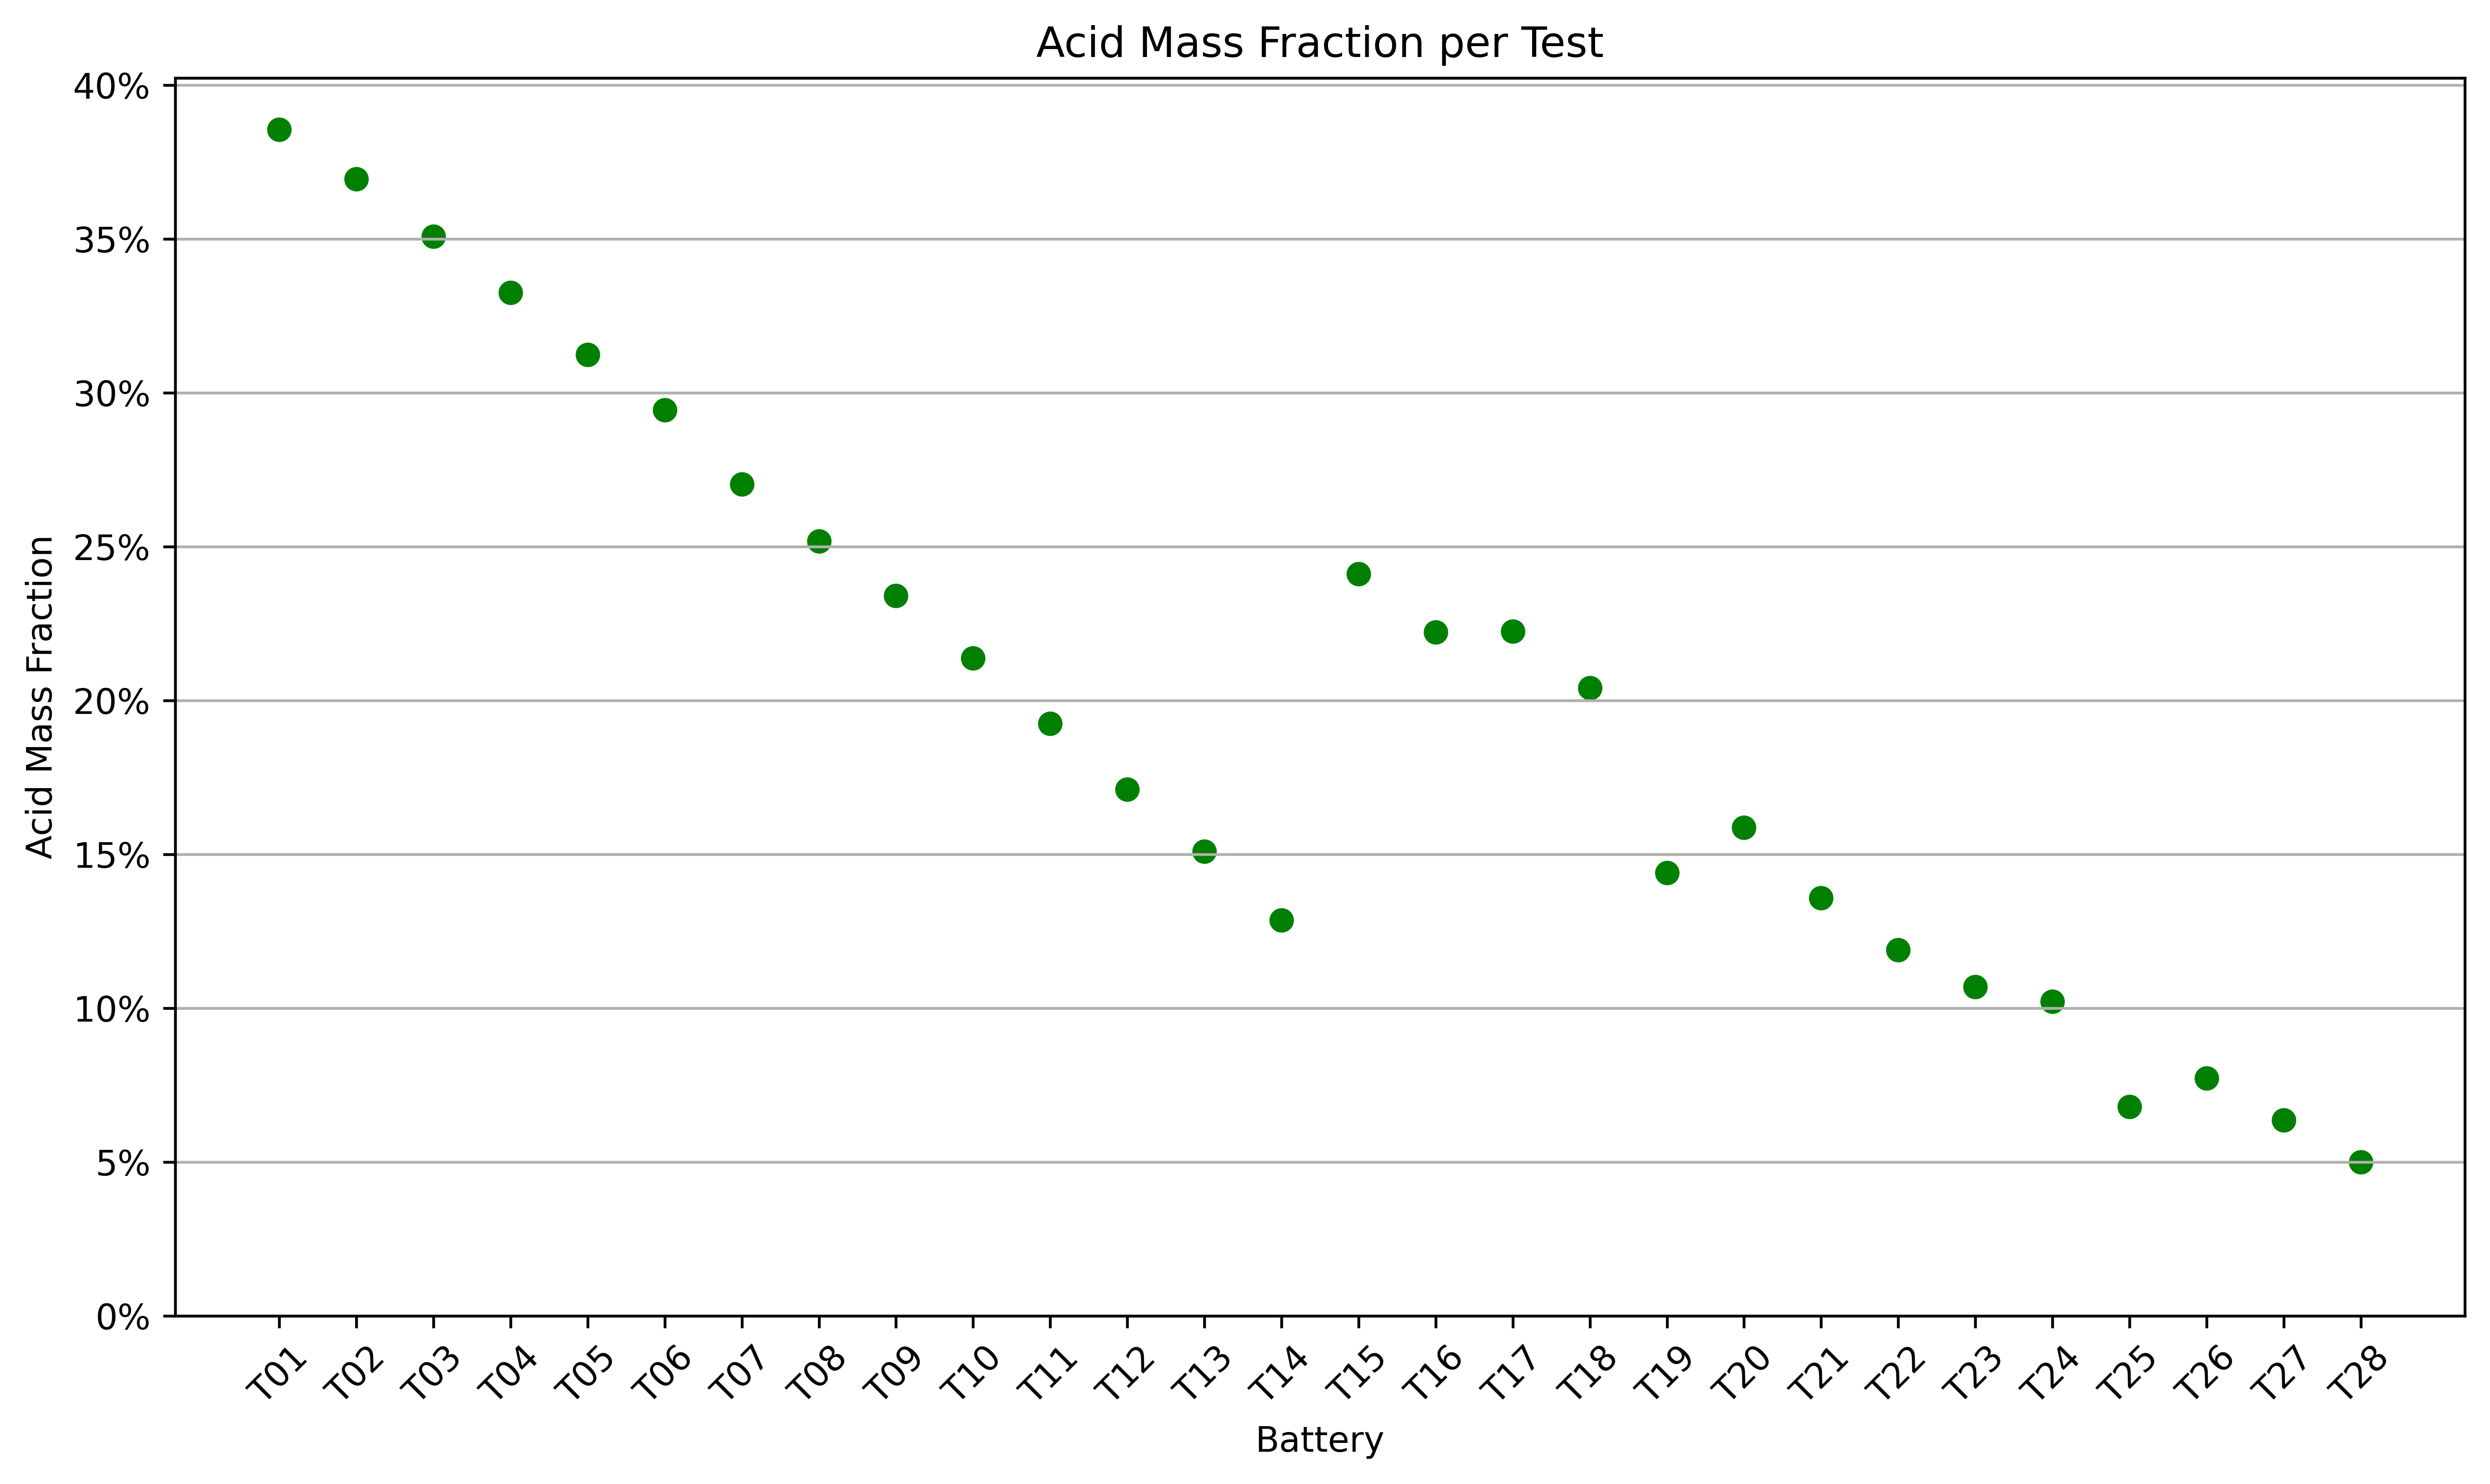

In [24]:
def electrolyte_mass_fraction(emf_ht: float):
    """
    Calculate the acid mass fraction based on the EMF at room temperature.
    """
    # From UCT002 electrolyte measurements as Published in Observations of Freezing Lead Acid Batteries using EIS, Stanton 2025
    return (emf_ht - 1.824) / 0.784


def plot_acid_concentration_per_test(vbatt_df: pd.DataFrame):
    tests = vbatt_df.index.tolist()
    acid_concentrations = [
        electrolyte_mass_fraction(vbatt_df.loc[test, "VBATT HT"] / 6) for test in tests
    ]

    plt.figure(figsize=(10, 6))
    plt.scatter(tests, acid_concentrations, color="green")
    plt.xlabel("Battery")
    plt.ylabel("Acid Mass Fraction")
    plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    plt.ylim(bottom=0)
    plt.title("Acid Mass Fraction per Test")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_acid_concentration_per_test(vbatt_df)

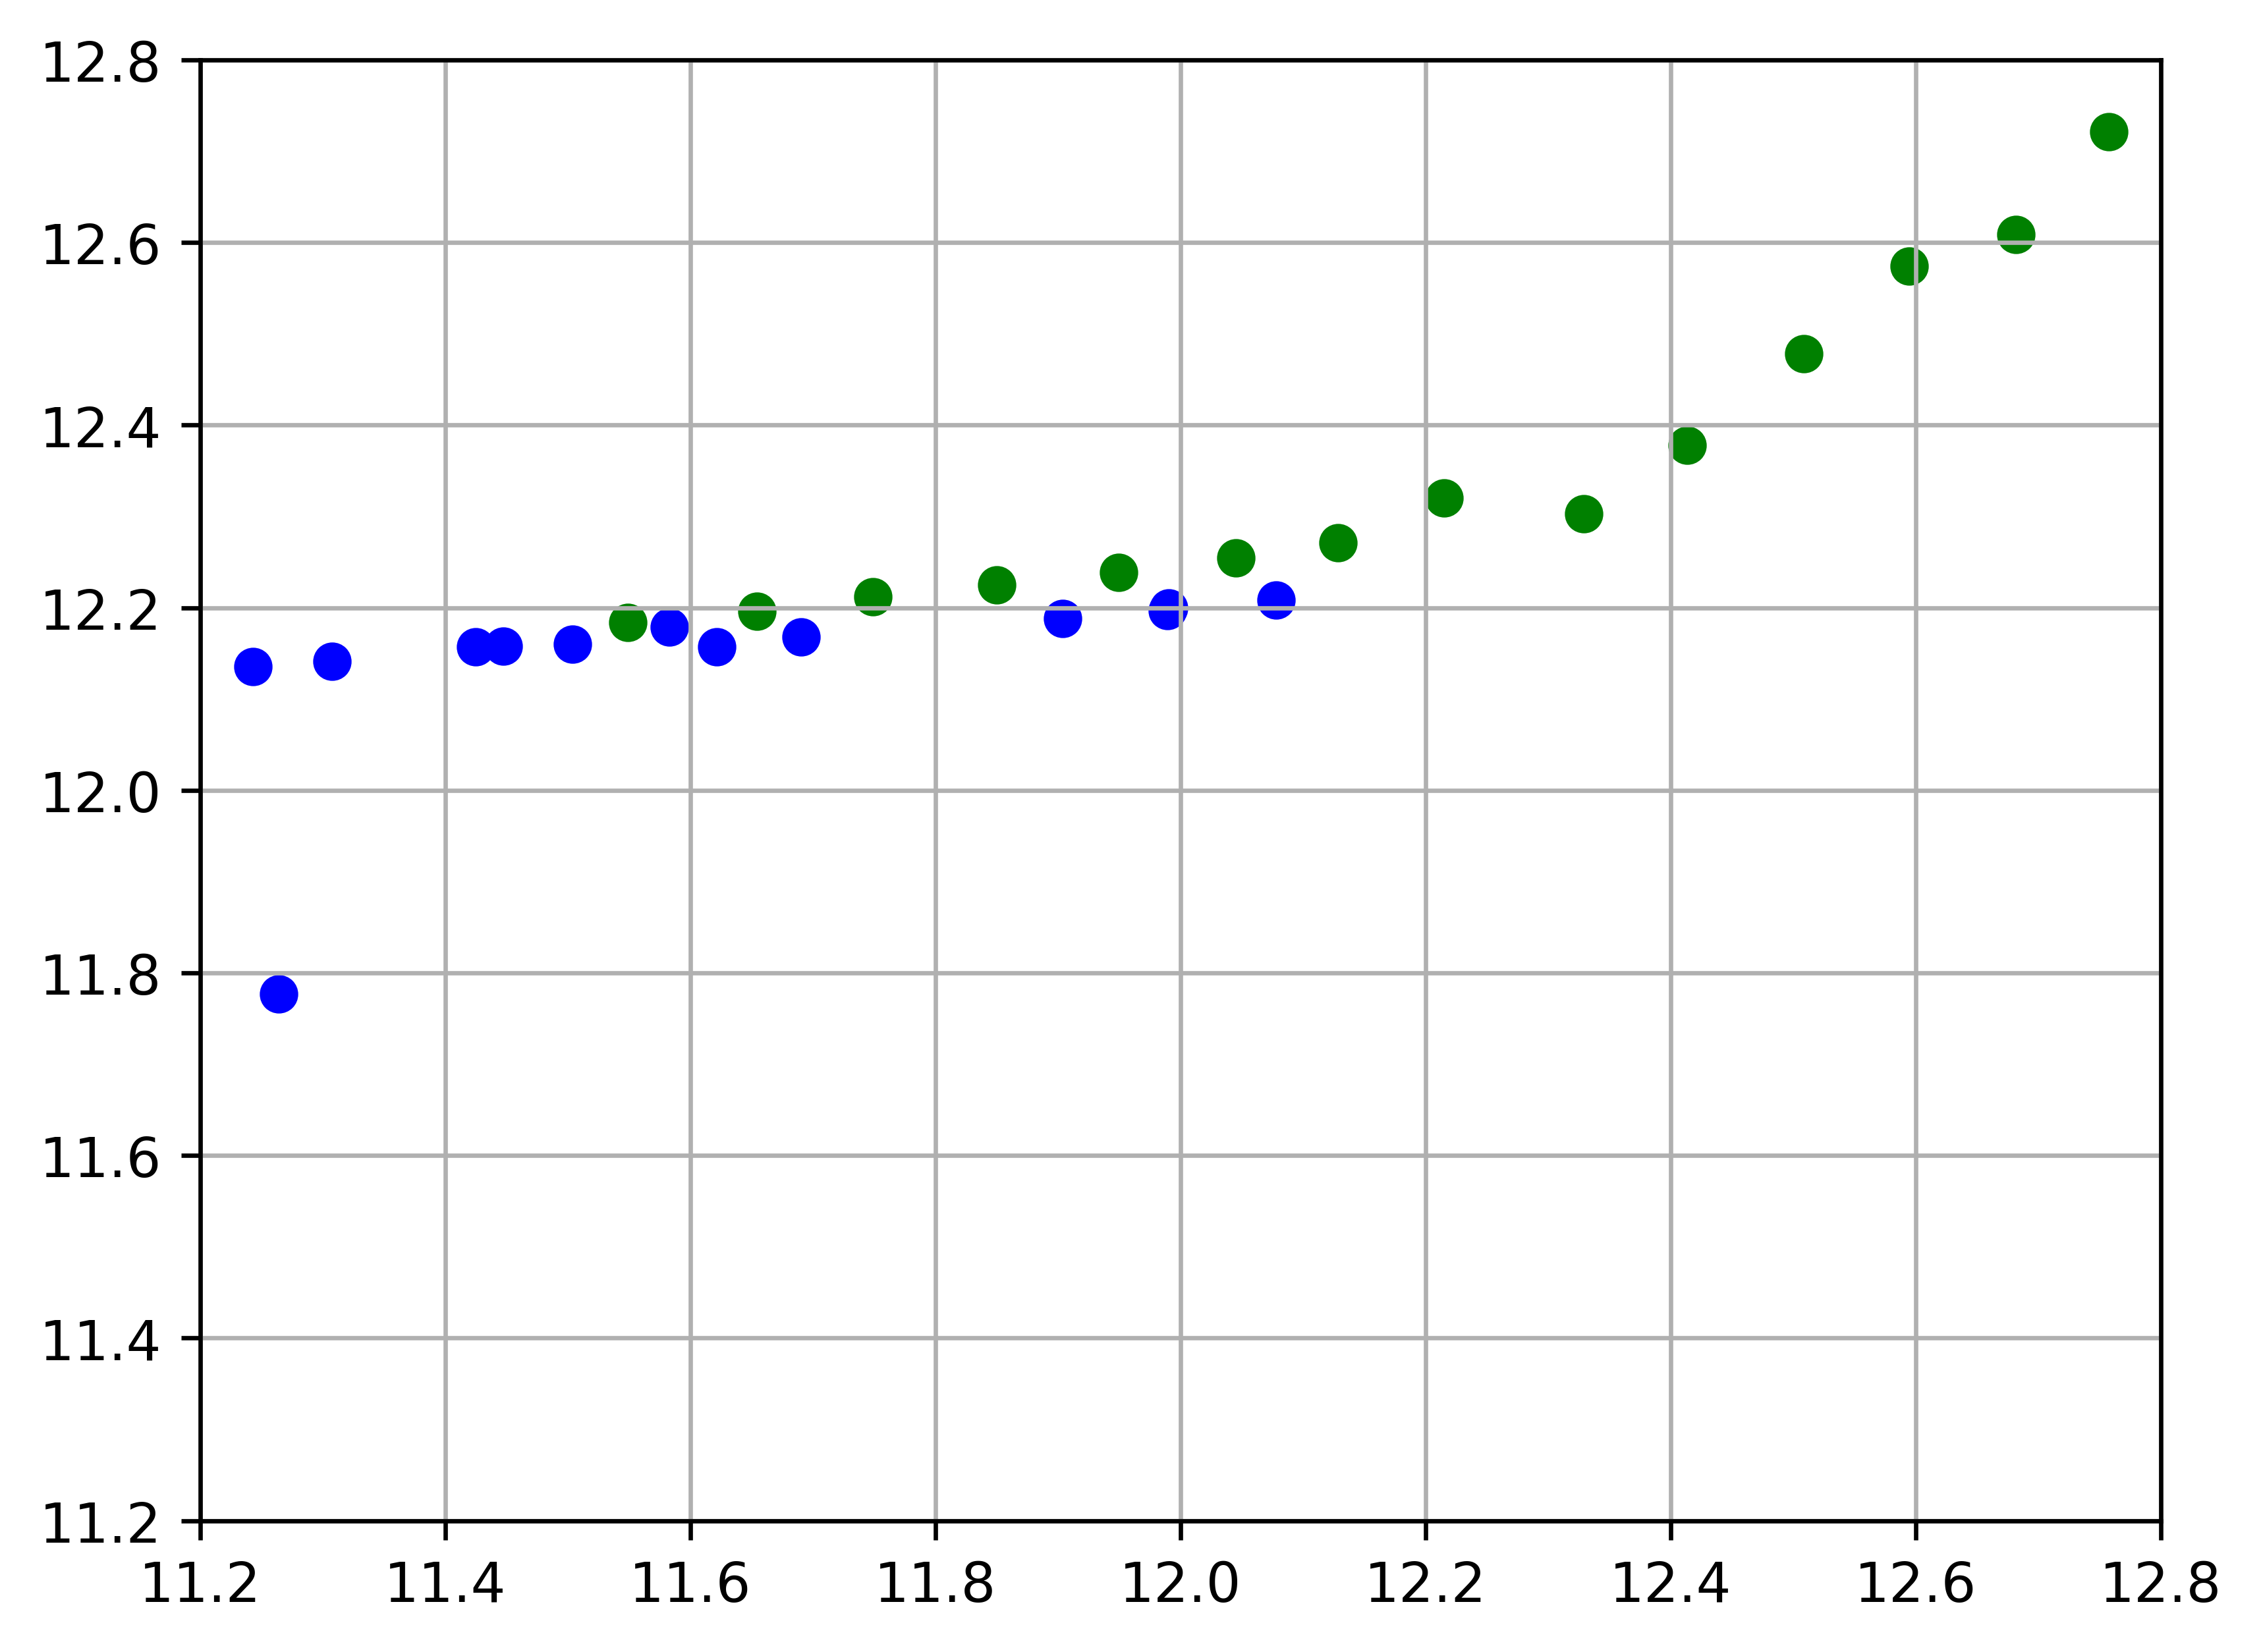

In [25]:
def plot_vbatt_change(vbatt_df: pd.DataFrame):
    for test in vbatt_df.index:
        vbatt_ht = vbatt_df.loc[test, "VBATT HT"]
        vbatt_lt = vbatt_df.loc[test, "VBATT LT"]

        plt.scatter(
            vbatt_ht,  # type: ignore
            vbatt_lt,  # type: ignore
            label=test,
            color="green" if int(test[1:]) < 15 else "blue",
        )

    plt.grid(axis="both")
    plt.xlim(11.2, 12.8)
    plt.ylim(11.2, 12.8)


plot_vbatt_change(vbatt_df)

## Freezing Extent

In [26]:
def freezing_extent(vbatt_ht: float, vbatt_lt: float) -> float:
    if vbatt_ht > vbatt_lt:
        return 0.0  # Negative Thermal Gradient, No Freezing

    OFFSET = 1.824  # Linear zero offset of Cell Voltage to Electrolyte Concentration
    f = 1 - (vbatt_ht - OFFSET) / (vbatt_lt - OFFSET)
    return f


freezing_extents = {}

for battery in vbatt_df.index:
    vbatt_ht = vbatt_df.loc[battery, "VBATT HT"] / 6  # type: ignore
    vbatt_lt = vbatt_df.loc[battery, "VBATT LT"] / 6  # type: ignore

    f = freezing_extent(vbatt_ht=vbatt_ht, vbatt_lt=vbatt_lt)  # type: ignore

    freezing_extents[battery] = f

freezing_extents_df = pd.DataFrame.from_dict(
    freezing_extents, orient="index", columns=["Freezing Extent"]
)
freezing_extents_df.index.name = "Battery"
pd.options.display.float_format = "{:,.2%}".format
print(freezing_extents_df)

         Freezing Extent
Battery                 
T01                0.00%
T02                0.00%
T03                0.00%
T04                0.00%
T05                0.00%
T06                0.00%
T07                7.64%
T08               10.73%
T09               15.96%
T10               22.30%
T11               29.28%
T12               36.51%
T13               43.28%
T14               51.20%
T15               10.31%
T16               16.57%
T17               16.67%
T18               22.85%
T19               44.15%
T20               39.00%
T21               48.26%
T22               53.96%
T23               58.53%
T24               60.34%
T25               61.58%
T26               69.64%
T27               74.90%
T28               81.74%


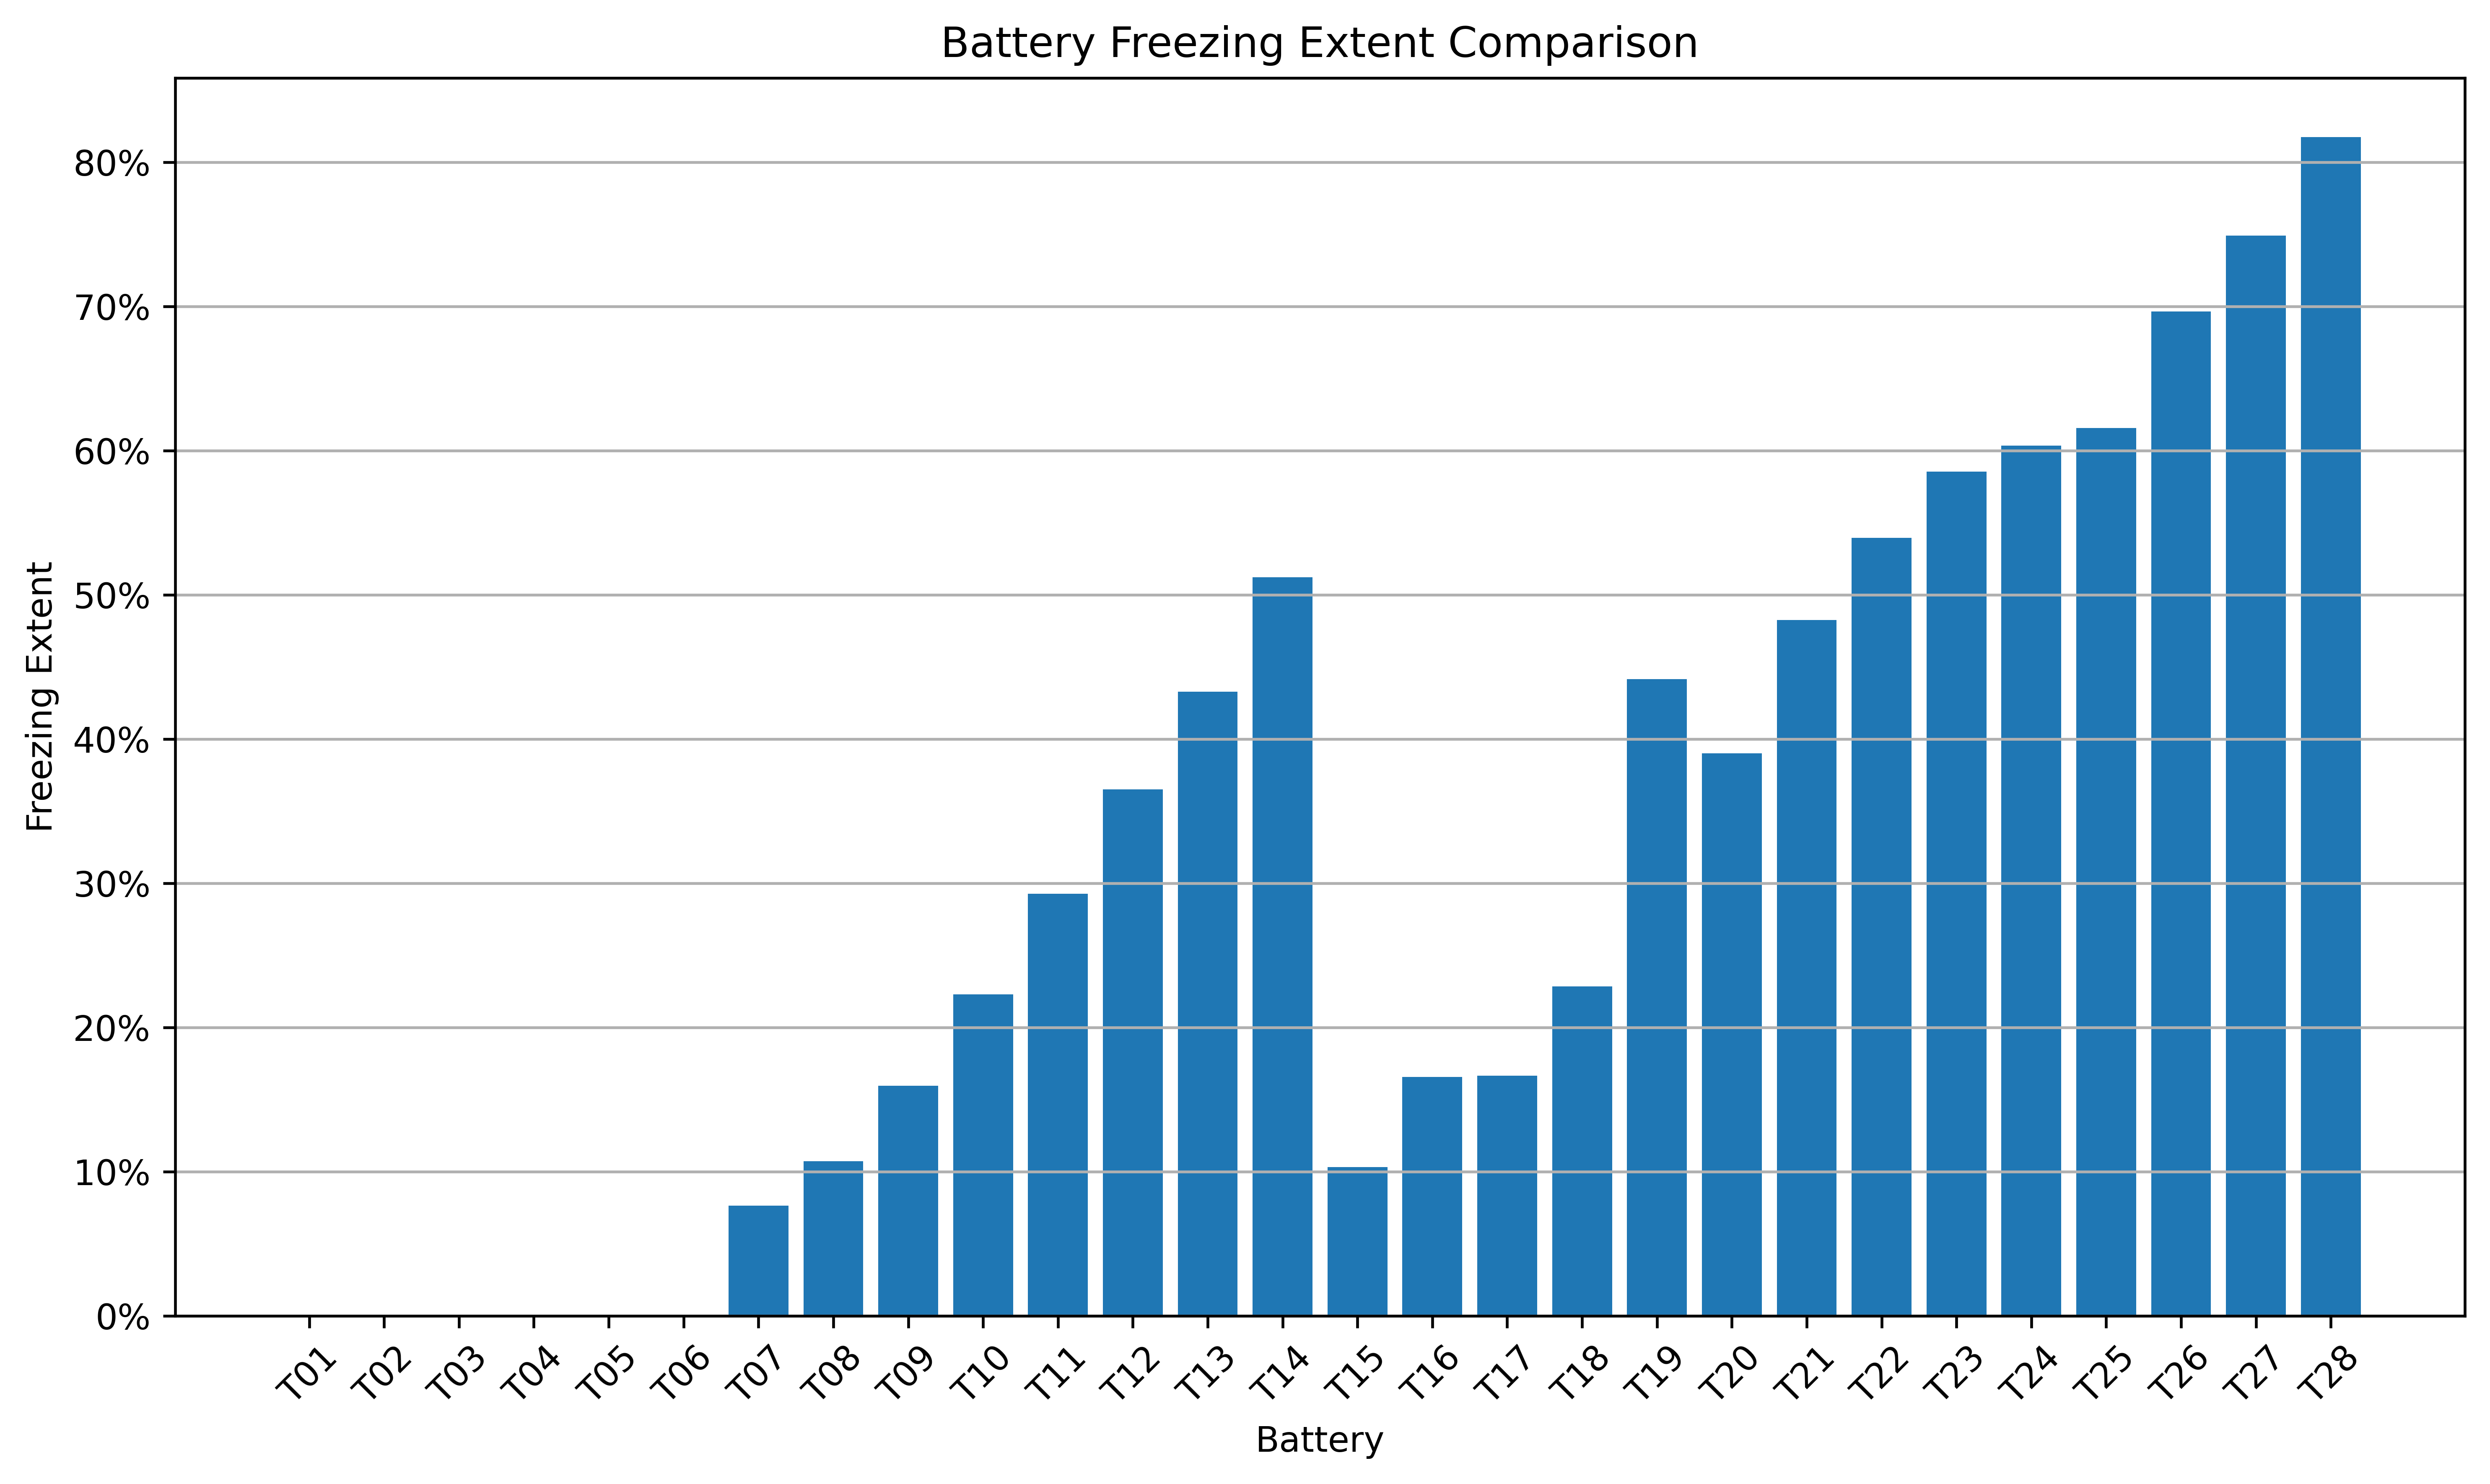

In [27]:
def plot_freezing_extents(freezing_extents: dict):
    batteries = list(freezing_extents.keys())
    freezing_values = list(freezing_extents.values())

    plt.figure(figsize=(10, 6))
    plt.bar(batteries, freezing_values)
    plt.xlabel("Battery")
    plt.ylabel("Freezing Extent")
    plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{100*y:.0f}%"))
    plt.title("Battery Freezing Extent Comparison")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_freezing_extents(freezing_extents)

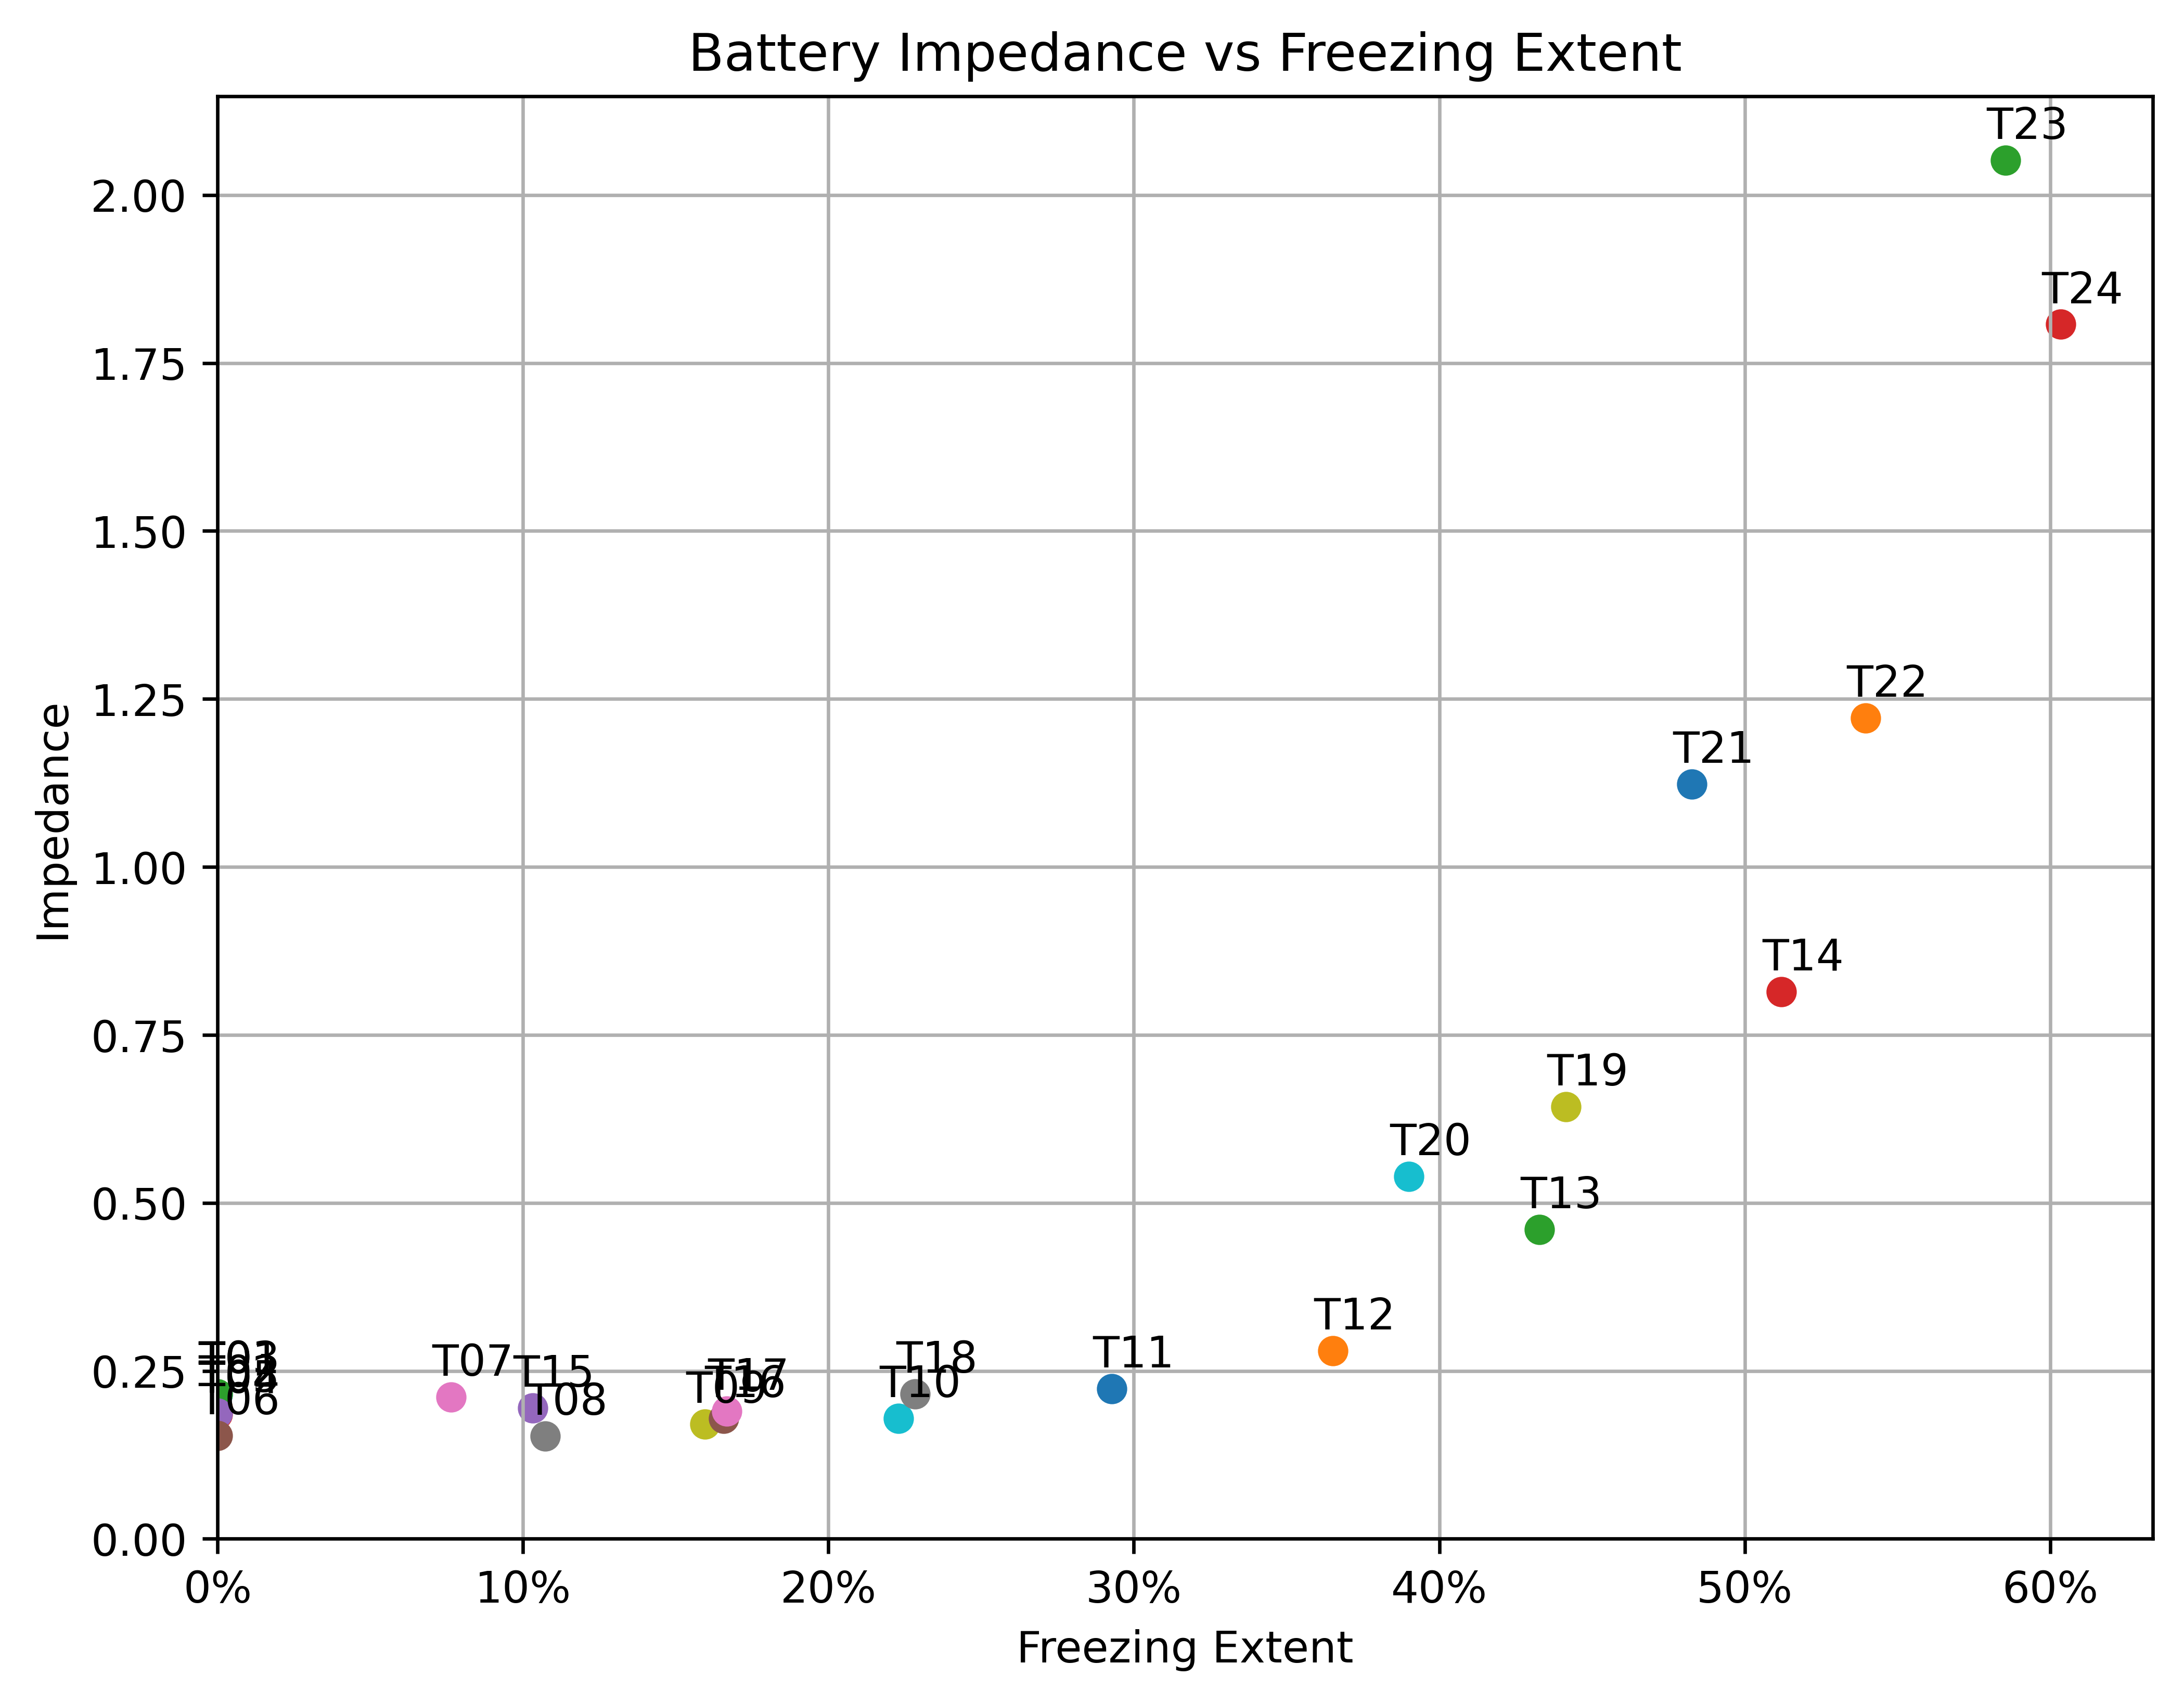

In [28]:
def plot_impedance_vs_freezing(
    impedances: dict,
    freezing_extents: dict,
    include_non_freezing: bool = False,
    filter_outliers: List[str] | None = None,
    annotate: bool = False,
) -> Figure:
    fig, ax = plt.subplots(
        figsize=(8, 6),
    )

    for test in impedances.keys():
        impedance_value = impedances[test]
        freezing_value = freezing_extents.get(test, 0.0)

        if filter_outliers and test in filter_outliers:
            continue

        if freezing_value > 0.0 or include_non_freezing:
            ax.scatter(
                freezing_value,
                impedance_value,
                label=test,
                color="black" if not annotate else None,
            )
            if annotate:
                ax.annotate(
                    test,
                    (freezing_value, impedance_value),
                    textcoords="offset points",
                    xytext=(5, 5),
                    ha="center",
                )

    plt.ylabel("Impedance")
    plt.xlabel("Freezing Extent")
    plt.title("Battery Impedance vs Freezing Extent")
    plt.grid()

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{100*x:.0f}%"))
    # ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.2f}Ω"))

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    # ax.set_xscale("log")
    # ax.set_yscale("log")

    return fig


OUTLIERS = ["T26", "T27", "T28"]
# OUTLIERS = ["T26"]

_ = plot_impedance_vs_freezing(
    impedances,
    freezing_extents,
    include_non_freezing=True,
    filter_outliers=OUTLIERS,
    annotate=True,
)

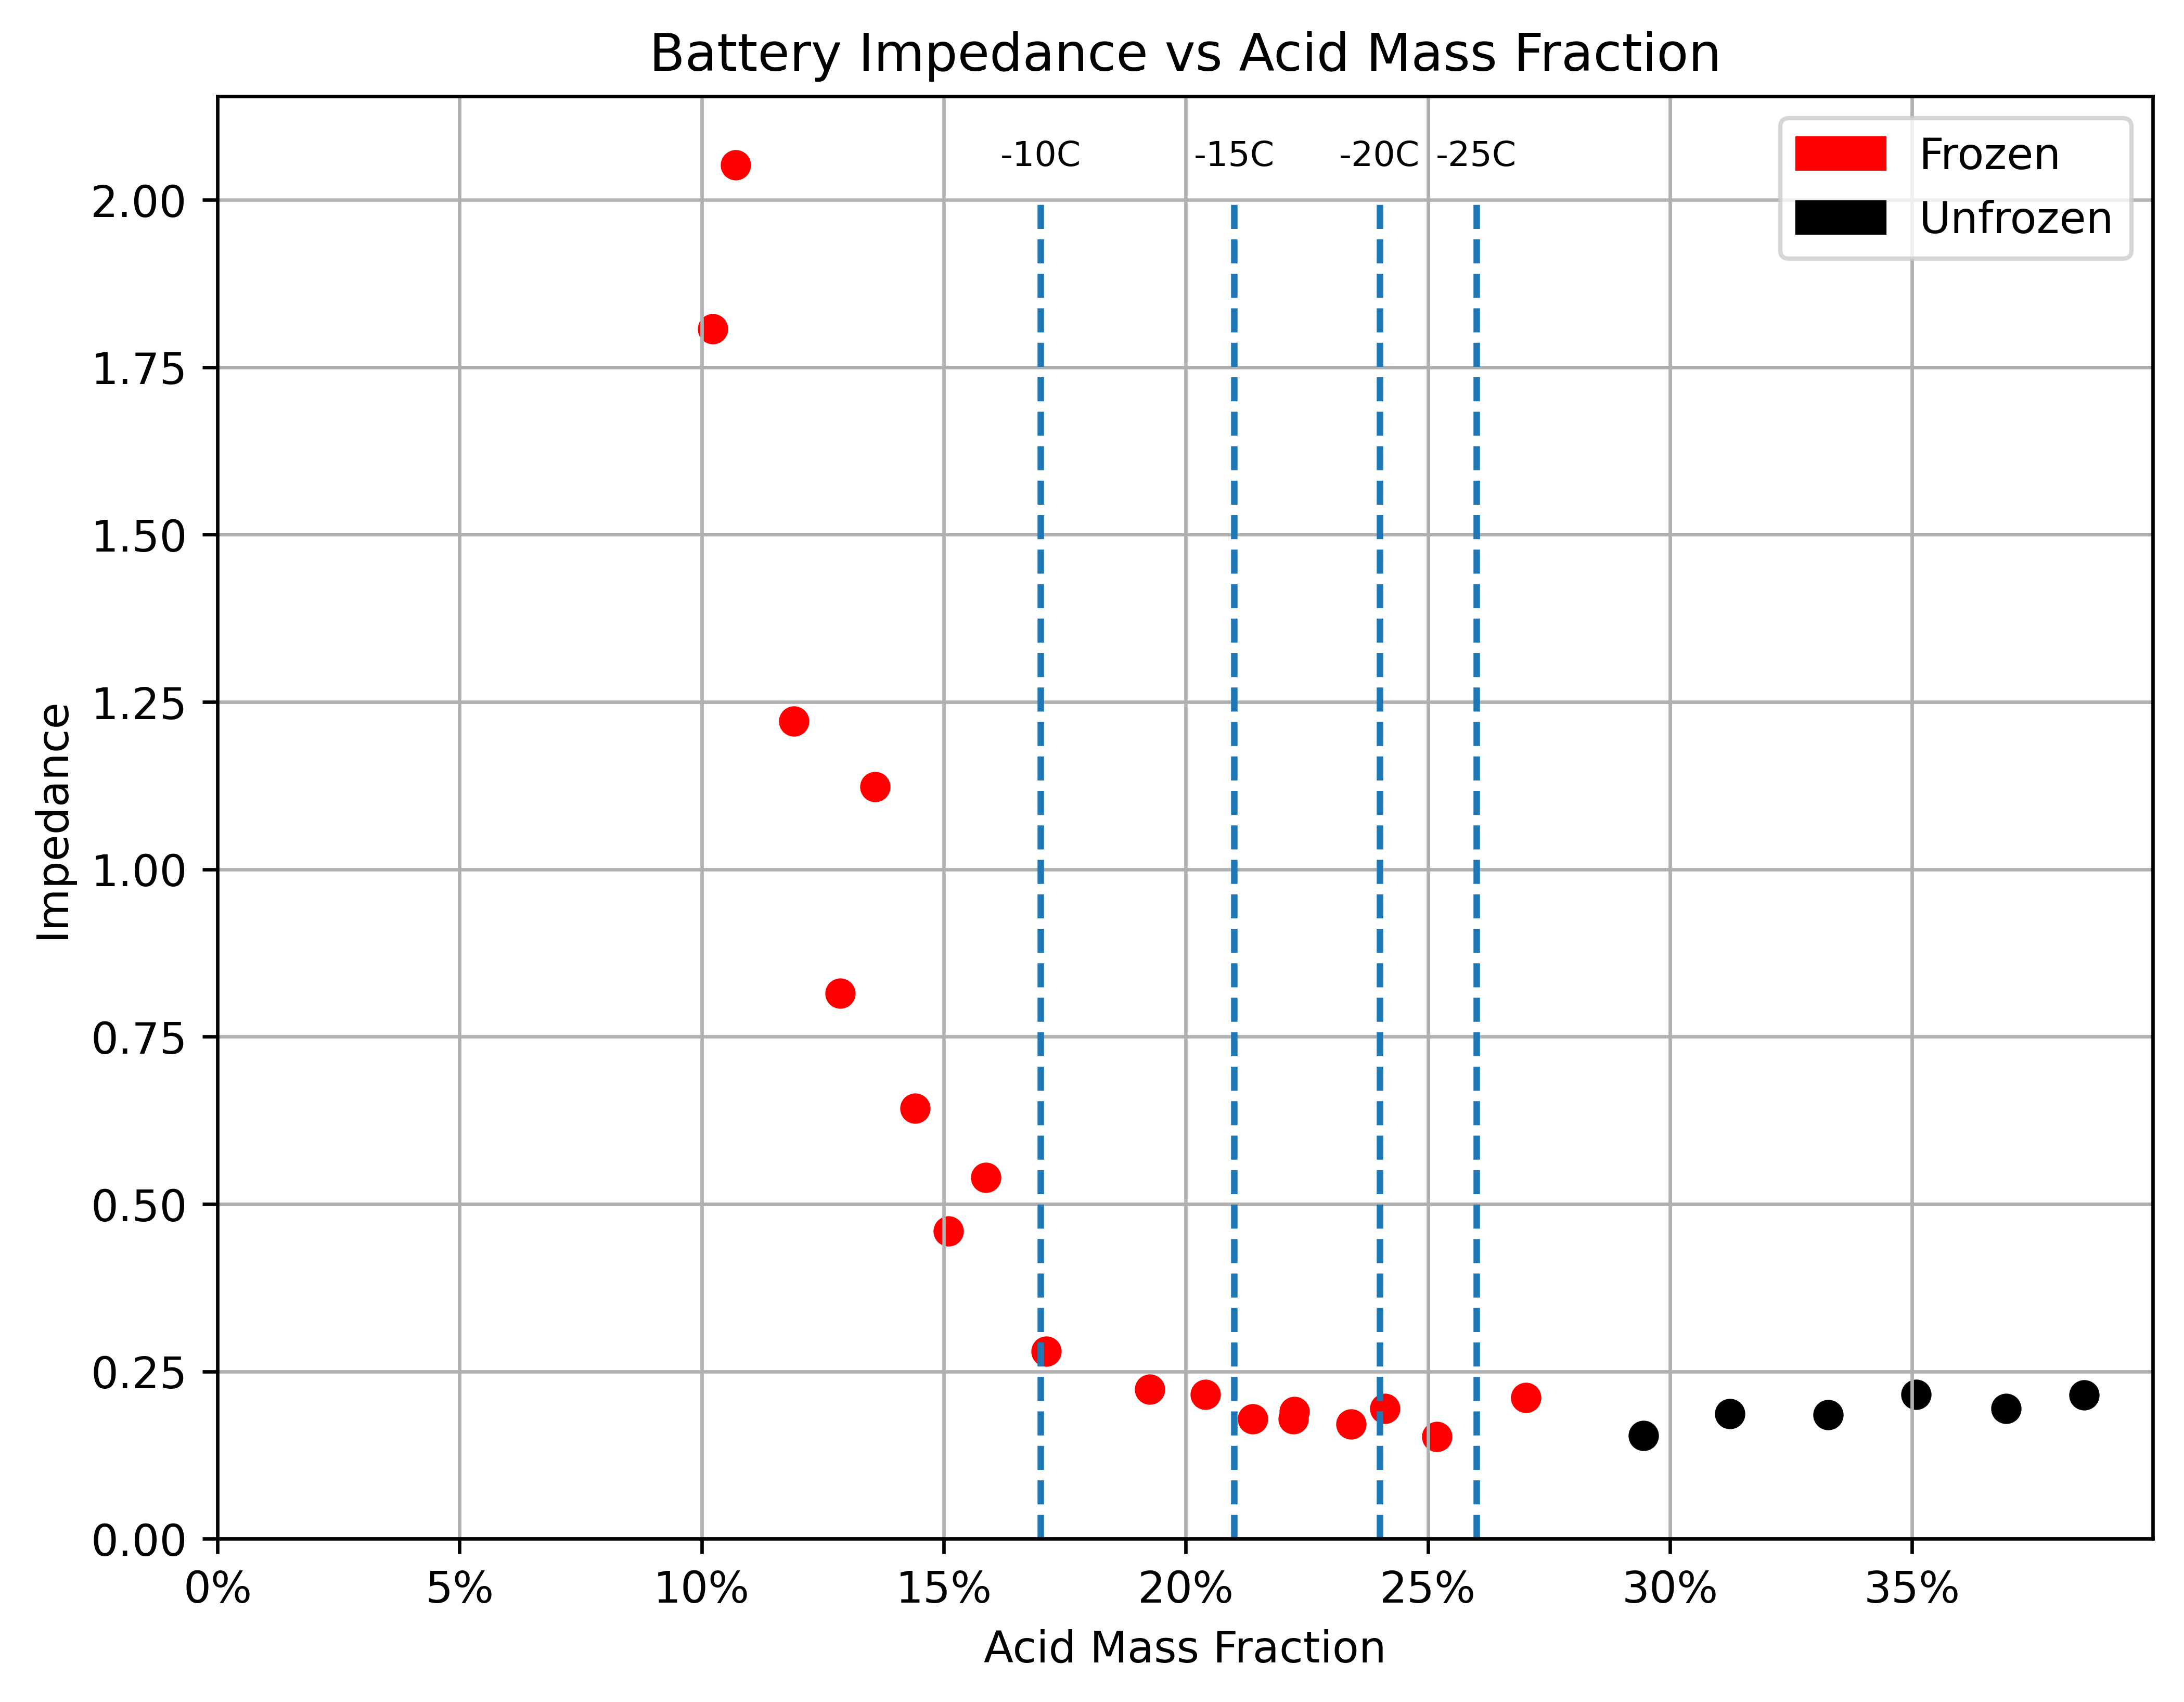

In [29]:
from matplotlib.patches import Patch


def plot_impedence_vs_concentration(
    impedances: dict,
    concentrations: dict,
    freezing_extents: dict,
    filter_outliers: List[str] | None = None,
) -> Figure:
    fig, ax = plt.subplots(
        figsize=(8, 6),
    )

    for test in impedances.keys():
        if filter_outliers and test in filter_outliers:
            continue

        impedance_value = impedances[test]
        concentration_value = concentrations.get(test, 0.0)

        ax.scatter(
            concentration_value,
            impedance_value,
            label=test,
            color="black" if freezing_extents.get(test, 0.0) == 0.0 else "red",
        )

    THRESHOLDS = [(-10, 0.17), (-15, 0.21), (-20, 0.24), (-25, 0.26)]

    for temp, conc in THRESHOLDS:
        plt.vlines(
            [conc],
            0,
            2,
            linestyle="--",
        )
        ax.annotate(
            f"{temp}C",
            (conc, ax.get_ylim()[1]),
            textcoords="offset points",
            xytext=(0, -10),
            ha="center",
            va="top",
            size=8,
        )

    plt.ylabel("Impedance")
    plt.xlabel("Acid Mass Fraction")
    plt.title("Battery Impedance vs Acid Mass Fraction")
    plt.grid()

    legend_handles = []
    if any(freezing_extents.get(t, 0.0) > 0.0 for t in impedances.keys()):
        legend_handles.append(Patch(color="red", label="Frozen"))
    if any(freezing_extents.get(t, 0.0) == 0.0 for t in impedances.keys()):
        legend_handles.append(Patch(color="black", label="Unfrozen"))
    if legend_handles:
        ax.legend(handles=legend_handles)

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    # ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.2f}Ω"))

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    # ax.set_xscale("log")
    # ax.set_yscale("log")

    return fig


concentrations = {
    test: electrolyte_mass_fraction(vbatt_df.loc[test, "VBATT HT"] / 6)  # type: ignore
    for test in impedances.keys()
}

_ = plot_impedence_vs_concentration(
    impedances,
    concentrations,
    freezing_extents,
    filter_outliers=OUTLIERS,
)

## Exports

Text(0.5, 1.0, '')

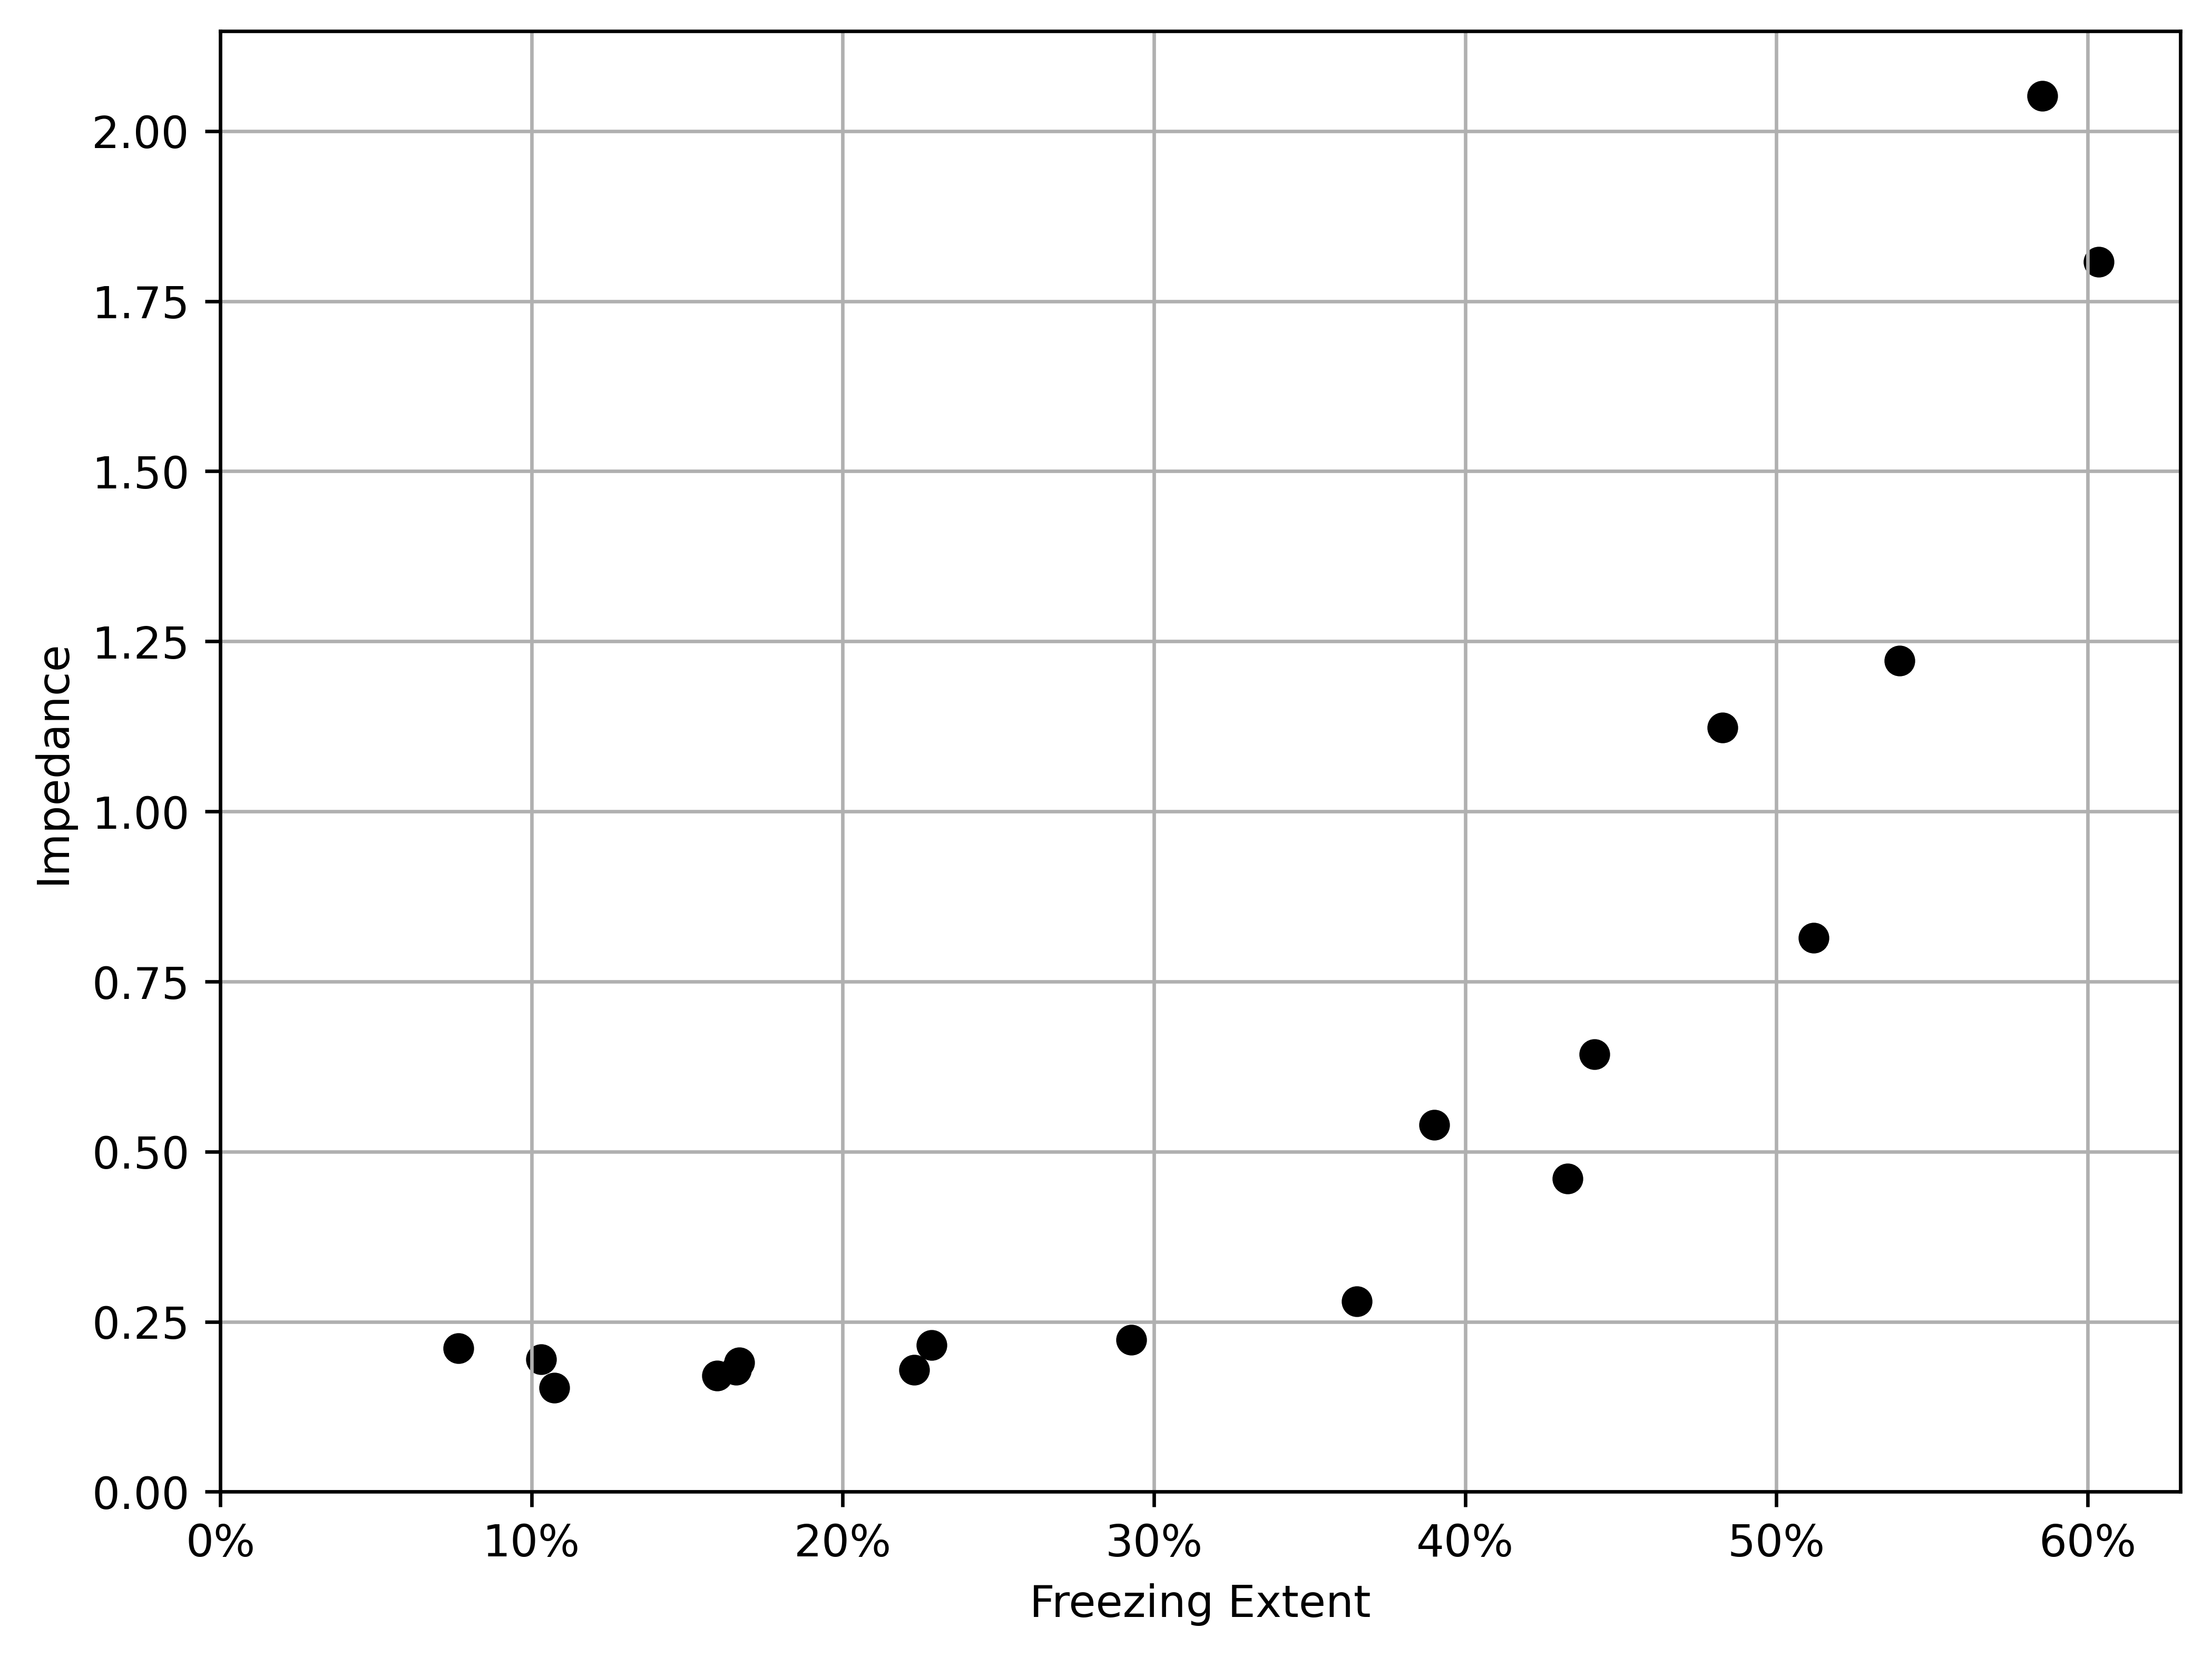

In [30]:
freezing_impedance_fig = plot_impedance_vs_freezing(
    impedances,
    freezing_extents,
    filter_outliers=OUTLIERS,
    annotate=False,
)

freezing_impedance_fig.axes[0].set_title("")